raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=["PM2.5", "AQI"])
print(df.shape)
# At Gate M1, replace all of the above with:  df = load_clean()

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from src.utils import *
set_plot_style()
print("setup ok")

setup ok


In [3]:
raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=["PM2.5", "AQI"])
print(df.shape)
df[["Date", "PM2.5", "AQI"]].head()

(1815, 16)


,Date,PM2.5,AQI
10229,2015-01-01,313.22,472.0
10230,2015-01-02,186.18,454.0
10231,2015-01-03,87.18,143.0
10232,2015-01-04,151.84,319.0
10233,2015-01-05,146.60,325.0


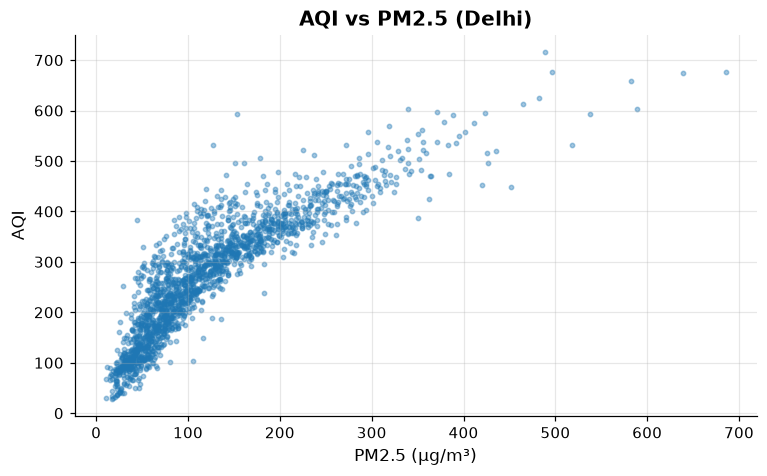

,PM2.5,AQI
PM2.5,1.000000,0.877582
AQI,0.877582,1.000000


In [4]:
fig, ax = plt.subplots()
ax.scatter(df["PM2.5"], df["AQI"], s=8, alpha=.4)
ax.set(title="AQI vs PM2.5 (Delhi)", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
plt.show()
df[["PM2.5", "AQI"]].corr()

In [5]:
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=SEED)
X_train = sm.add_constant(train[["PM2.5"]])
model = sm.OLS(train["AQI"], X_train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AQI   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     4952.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:39:52   Log-Likelihood:                -7940.4
No. Observations:                1452   AIC:                         1.588e+04
Df Residuals:                    1450   BIC:                         1.590e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        113.7549      2.652     42.896      0.0

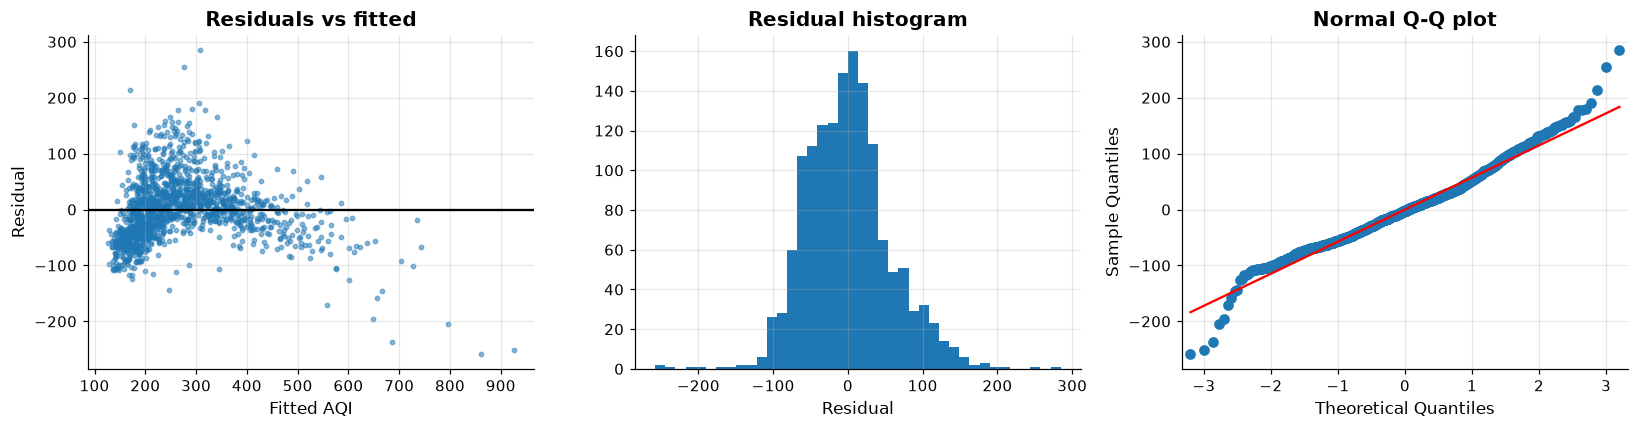

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(model.fittedvalues, model.resid, s=8, alpha=.5)
ax[0].axhline(0, color="k")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted AQI", ylabel="Residual")
ax[1].hist(model.resid, bins=40)
ax[1].set(title="Residual histogram", xlabel="Residual")
sm.qqplot(model.resid, line="s", ax=ax[2])
ax[2].set_title("Normal Q-Q plot")
plt.tight_layout()
plt.show()

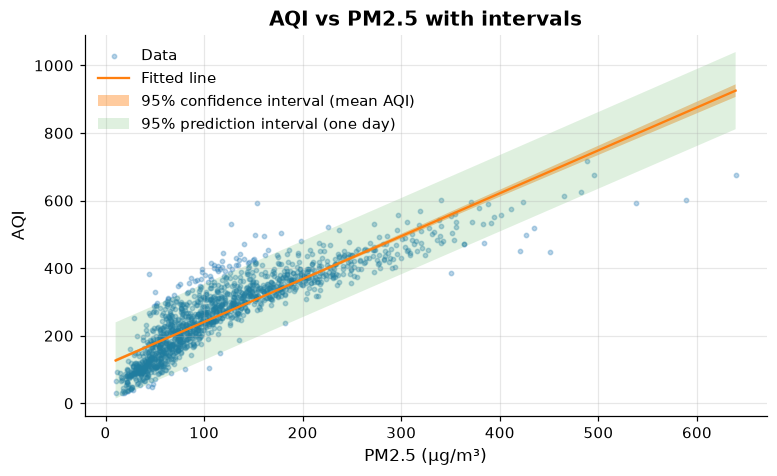

In [7]:
grid = pd.DataFrame({"PM2.5": np.linspace(train["PM2.5"].min(), train["PM2.5"].max(), 100)})
fr = model.get_prediction(sm.add_constant(grid)).summary_frame(alpha=1 - CONF_LEVEL)
fig, ax = plt.subplots()
ax.scatter(train["PM2.5"], train["AQI"], s=8, alpha=.3, label="Data")
ax.plot(grid["PM2.5"], fr["mean"], color="C1", label="Fitted line")
ax.fill_between(grid["PM2.5"], fr["mean_ci_lower"], fr["mean_ci_upper"], alpha=.4,
                label="95% confidence interval (mean AQI)")
ax.fill_between(grid["PM2.5"], fr["obs_ci_lower"], fr["obs_ci_upper"], alpha=.15,
                label="95% prediction interval (one day)")
ax.set(title="AQI vs PM2.5 with intervals", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
ax.legend()
plt.show()

In [8]:
from statsmodels.stats.diagnostic import het_breuschpagan
lm, lm_p, f, f_p = het_breuschpagan(model.resid, model.model.exog)
print(f"Breusch-Pagan p-value: {lm_p:.4f}")

Breusch-Pagan p-value: 0.0002


In [9]:
pred = model.predict(sm.add_constant(test[["PM2.5"]]))
results = [{"Model": "Simple linear (PM2.5)", **regression_metrics(test["AQI"], pred, n_features=1)}]
pd.DataFrame(results)

,Model,R2,Adj_R2,RMSE,MAE
0,Simple linear (PM2.5),0.752803,0.752118,56.45243,41.822695


In [10]:
# 1. Build the data (the raw file has gaps in some pollutants, so drop them for now)
dfm = df.dropna(subset=POLLUTANTS + ["AQI"]).copy()
dfm["Month"] = dfm["Date"].dt.month
dfm["Season"] = dfm["Month"].map(season_of)
print(dfm.shape)

(1698, 18)


In [11]:
# 2. Predictors: 9 pollutants + season dummies (Winter is the baseline)
season_d = pd.get_dummies(dfm["Season"]).drop(columns="Winter").astype(float)
X_all = pd.concat([dfm[POLLUTANTS], season_d], axis=1)
y_all = dfm["AQI"]
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=SEED)
model_m = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(model_m.summary())

                            OLS Regression Results                            
Dep. Variable:                    AQI   R-squared:                       0.875
Model:                            OLS   Adj. R-squared:                  0.873
Method:                 Least Squares   F-statistic:                     781.5
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:49:40   Log-Likelihood:                -6942.2
No. Observations:                1358   AIC:                         1.391e+04
Df Residuals:                    1345   BIC:                         1.398e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           82.4050      5.563     14.812   

In [12]:
print(f"R-squared:     {model_m.rsquared:.3f}")
print(f"Adj R-squared: {model_m.rsquared_adj:.3f}")
print(f"F-test p:      {model_m.f_pvalue:.2e}")
print(model_m.params[["Summer", "Monsoon", "Post-monsoon"]].round(2))

R-squared:     0.875
Adj R-squared: 0.873
F-test p:      0.00e+00
Summer         -11.74
Monsoon        -25.71
Post-monsoon     0.86
dtype: float64


In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xc = sm.add_constant(X_tr)
vif = pd.DataFrame({"Variable": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
vif[vif["Variable"] != "const"].sort_values("VIF", ascending=False)

,Variable,VIF
1,PM2.5,5.111041
4,NO2,4.969783
2,PM10,4.365286
3,NO,3.912354
10,Monsoon,2.718742
8,SO2,2.501361
12,Summer,2.394894
5,NOx,1.963258
6,NH3,1.846185
9,O3,1.630461


In [14]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
bp = het_breuschpagan(model_m.resid, model_m.model.exog)
print(f"Breusch-Pagan p = {bp[1]:.4g}")
print(f"Durbin-Watson   = {durbin_watson(model_m.resid.sort_index()):.2f}")

Breusch-Pagan p = 6.623e-12
Durbin-Watson   = 1.20


In [15]:
cooks = model_m.get_influence().cooks_distance[0]
print(f"Points above 4/n: {(cooks > 4/len(cooks)).sum()} of {len(cooks)}")

Points above 4/n: 92 of 1358


R2 (log scale): 0.807 | Breusch-Pagan p = 1.982e-16


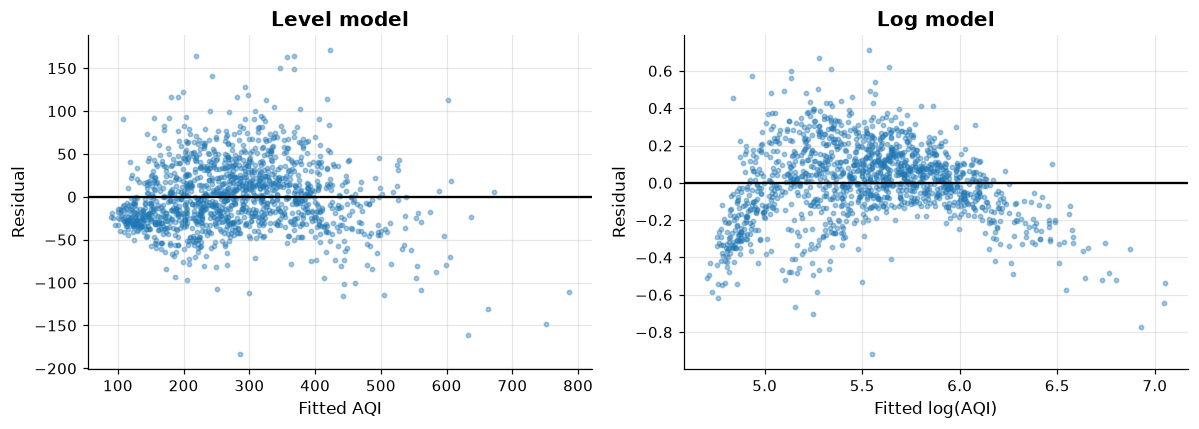

Level model: {'R2': 0.8670768834018185, 'Adj_R2': 0.8621989708661055, 'RMSE': 42.11754934374566, 'MAE': 30.825877547862103}
Log model:   {'R2': 0.38276048925622774, 'Adj_R2': 0.3601094980362728, 'RMSE': 90.75899847100374, 'MAE': 47.879960818106944}


In [16]:
y_tr_log = np.log(y_tr)
model_log = sm.OLS(y_tr_log, sm.add_constant(X_tr)).fit()
bp_log = het_breuschpagan(model_log.resid, model_log.model.exog)
print(f"R2 (log scale): {model_log.rsquared:.3f} | Breusch-Pagan p = {bp_log[1]:.4g}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(model_m.fittedvalues, model_m.resid, s=8, alpha=.4)
ax[0].axhline(0, color="k"); ax[0].set(title="Level model", xlabel="Fitted AQI", ylabel="Residual")
ax[1].scatter(model_log.fittedvalues, model_log.resid, s=8, alpha=.4)
ax[1].axhline(0, color="k"); ax[1].set(title="Log model", xlabel="Fitted log(AQI)", ylabel="Residual")
plt.tight_layout(); plt.show()

k = X_te.shape[1]
print("Level model:", regression_metrics(y_te, model_m.predict(sm.add_constant(X_te)), n_features=k))
print("Log model:  ", regression_metrics(y_te, np.exp(model_log.predict(sm.add_constant(X_te))), n_features=k))

In [17]:
model_rob = sm.OLS(y_tr, sm.add_constant(X_tr)).fit(cov_type="HC3")
pd.DataFrame({"coef": model_m.params, "p classic": model_m.pvalues,
              "p robust": model_rob.pvalues}).round(4)

,coef,p classic,p robust
const,82.4050,0.0000,0.0000
PM2.5,0.5215,0.0000,0.0000
PM10,0.4404,0.0000,0.0000
NO,-0.1375,0.0282,0.0769
NO2,0.4117,0.0002,0.0047
NOx,0.0542,0.1897,0.2566
NH3,-0.4156,0.0000,0.0001
CO,7.2224,0.0000,0.0000
SO2,0.1713,0.4157,0.5279
O3,0.2516,0.0000,0.0000


In [18]:
def fit_ols(cols):
    return sm.OLS(y_tr, sm.add_constant(X_tr[cols])).fit()

sets = {"Full (12)": list(X_tr.columns),
        "Drop NOx, SO2": [c for c in X_tr.columns if c not in ("NOx", "SO2")]}
rows = []
for name, cols in sets.items():
    m = fit_ols(cols)
    rows.append({"Model": name, "k": len(cols), "Adj_R2": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic})
pd.DataFrame(rows).round(3)

,Model,k,Adj_R2,AIC,BIC
0,Full (12),12,0.873,13910.360,13978.139
1,"Drop NOx, SO2",10,0.873,13908.459,13965.810


In [19]:
infl = pd.DataFrame({"Cooks": cooks}, index=X_tr.index)
infl.sort_values("Cooks", ascending=False).head(5).join(dfm[["Date", "AQI", "PM2.5", "PM10"]])

,Cooks,Date,AQI,PM2.5,PM10
11015,0.087945,2017-02-25,516.0,425.22,103.74
10229,0.066394,2015-01-01,472.0,313.22,607.98
11490,0.062443,2018-06-15,593.0,153.28,613.34
10903,0.051217,2016-11-05,603.0,588.39,763.58
10904,0.049299,2016-11-06,676.0,685.36,708.80


In [20]:
final_cols = [c for c in X_tr.columns if c not in ("NOx", "SO2")]   # adjust to your choice in step 3
mf = fit_ols(final_cols)
pred_f = mf.predict(sm.add_constant(X_te[final_cols]))
results.append({"Model": "Multiple linear", **regression_metrics(y_te, pred_f, n_features=len(final_cols))})

In [21]:
pm_mean = X_tr["PM2.5"].mean()

def poly_design(X):
    Z = X[final_cols].copy()
    Z["PM2.5"] = X["PM2.5"] - pm_mean          # centred PM2.5 replaces the raw column
    Z["PM2.5_sq"] = Z["PM2.5"] ** 2
    return sm.add_constant(Z)

model_poly = sm.OLS(y_tr, poly_design(X_tr)).fit()
print(model_poly.summary().tables[1])
print(f"AIC: multiple = {mf.aic:.1f} | polynomial = {model_poly.aic:.1f}")

pred_poly = model_poly.predict(poly_design(X_te))
results.append({"Model": "Polynomial (PM2.5 squared)",
                **regression_metrics(y_te, pred_poly, n_features=len(final_cols) + 1)})

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          169.5052      6.316     26.837      0.000     157.115     181.896
PM2.5            0.8658      0.043     20.086      0.000       0.781       0.950
PM10             0.3688      0.019     18.953      0.000       0.331       0.407
NO              -0.1165      0.057     -2.038      0.042      -0.229      -0.004
NO2              0.3665      0.100      3.657      0.000       0.170       0.563
NH3             -0.4362      0.079     -5.529      0.000      -0.591      -0.281
CO               6.8037      0.477     14.273      0.000       5.869       7.739
O3               0.2355      0.047      4.987      0.000       0.143       0.328
Monsoon          0.8664      4.495      0.193      0.847      -7.952       9.685
Post-monsoon     8.8047      3.423      2.572      0.010       2.090      15.519
Summer           5.7958     

In [22]:
comp = pd.DataFrame(results).round(3)
save_table(comp, "regression_comparison")
comp

,Model,R2,Adj_R2,RMSE,MAE
0,Simple linear (PM2.5),0.753,0.752,56.452,41.823
1,Multiple linear,0.866,0.862,42.288,31.044
2,Polynomial (PM2.5 squared),0.881,0.877,39.777,29.286


In [23]:
cols_noseason = [c for c in poly_design(X_tr).columns if c not in ("Monsoon", "Post-monsoon", "Summer")]
no_season = sm.OLS(y_tr, poly_design(X_tr)[cols_noseason]).fit()
f, p, df_diff = model_poly.compare_f_test(no_season)
print(f"Season jointly: F = {f:.2f}, p = {p:.4g}, df = {int(df_diff)}")

Season jointly: F = 3.11, p = 0.02553, df = 3
